# 02 — Language and Social Integration

**Project:** Machine Learning Analysis of Life Satisfaction Among Foreign Residents in Seoul

**Research question:** How are Korean proficiency, residence duration, and belonging associated with overall life satisfaction?

**Shared contract:** Q11 regression; `high_satisfaction = (Q11 >= 8)` classification; original 80/20 stratified split from Notebook 01; 5-fold CV on training only. No new split and no direct edits to raw data.

The analysis uses an **observational survey**, so results describe association and predictive ability, not causation.

## 1. Setup and shared model configuration

The project module stores common hyperparameters and evaluation procedures used in all role notebooks. Run `pip install -e .` once after copying the files.

In [12]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p/'data'/'processed'/'seoul_foreigners_modeling_master.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run notebooks/01_preprocessing.ipynb first to generate data/processed files.')
sys.path.insert(0, str(ROOT/'src'))
from seoul_foreigners_ml.team_experiments import (
    RANDOM_STATE, CV_FOLDS, load_shared_data, validate_features,
    cv_compare, evaluate_winner, feature_permutation
)
RESULTS_DIR = ROOT/'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)
print('Random state:', RANDOM_STATE, 'CV folds:', CV_FOLDS)

Project root: C:\Users\laura\OneDrive\Laura\Uni\3년\2학기\Machine Learning\Final Project\seoul_foreigners_ml_project
Random state: 42 CV folds: 5


## 2. Load the shared modeling dataset and original split

The same respondents and row identities are used across all three notebooks.

In [13]:
root, df, train_df, test_df = load_shared_data(ROOT)
print('Master:', df.shape)
print('Train:', train_df.shape)
print('Test:', test_df.shape)
print('Class proportions:', df['high_satisfaction'].value_counts(normalize=True).sort_index().round(4).to_dict())
assert len(train_df)==2000 and len(test_df)==500

Master: (2500, 165)
Train: (2000, 165)
Test: (500, 165)
Class proportions: {0: 0.3448, 1: 0.6552}


## 3. Research features and data types

Nominal survey codes are treated as categories. Ordinal scores are modeled numerically (an approximation whose limitations must be discussed). Numeric features are imputed and standardized in the model pipeline. Review official codebook labels before substantive interpretation.

In [14]:
NOMINAL = ['SQ1', 'SQ2', 'SQ7']
ORDINAL = ['Q19_1', 'Q19_2', 'Q19_3', 'Q19_4', 'Q20_1', 'Q20_2', 'Q20_3', 'Q20_4']
NUMERIC = ['age', 'months_in_korea_log1p', 'korean_proficiency_10']
FEATURES = validate_features(df, NOMINAL, ORDINAL, NUMERIC)
feature_table = pd.DataFrame([{'feature':col,'kind':kind,'missing_pct':round(df[col].isna().mean()*100,2),'n_unique':df[col].nunique(dropna=True)}
    for kind,columns in [('nominal',NOMINAL),('ordinal',ORDINAL),('numeric',NUMERIC)] for col in columns])
display(feature_table)

,feature,kind,missing_pct,n_unique
0,SQ1,nominal,0.0,10
1,SQ2,nominal,0.0,9
2,SQ7,nominal,0.0,2
3,Q19_1,ordinal,0.0,5
4,Q19_2,ordinal,0.0,5
5,Q19_3,ordinal,0.0,5
6,Q19_4,ordinal,0.0,5
7,Q20_1,ordinal,0.0,5
8,Q20_2,ordinal,0.0,5
9,Q20_3,ordinal,0.0,5


### Interpretation note

Q19 and Q20 are belonging/integration survey item families. Verify the direction and exact Korean text of each item in the original codebook before making substantive interpretations. Do not mix the combined Korean proficiency score with Q1_1–Q1_4 in the same baseline.

If the codebook contradicts a proposed type, update the role's `NOMINAL`, `ORDINAL`, and `NUMERIC` lists and document the change in the findings file **before** training models.

## 4. Missingness and descriptive analysis

Missingness is reported before imputation. Survey skip logic may produce not-applicable responses; do not assume missing-at-random.

In [15]:
display(feature_table.sort_values('missing_pct',ascending=False))
print('Q11:', df['Q11'].describe().to_dict())
print('High satisfaction share:', round(df['high_satisfaction'].mean(),4))

,feature,kind,missing_pct,n_unique
0,SQ1,nominal,0.0,10
1,SQ2,nominal,0.0,9
2,SQ7,nominal,0.0,2
3,Q19_1,ordinal,0.0,5
4,Q19_2,ordinal,0.0,5
5,Q19_3,ordinal,0.0,5
6,Q19_4,ordinal,0.0,5
7,Q20_1,ordinal,0.0,5
8,Q20_2,ordinal,0.0,5
9,Q20_3,ordinal,0.0,5


Q11: {'count': 2500.0, 'mean': 7.7684, 'std': 1.1306957279178393, 'min': 0.0, '25%': 7.0, '50%': 8.0, '75%': 8.0, 'max': 10.0}
High satisfaction share: 0.6552


## 5. Exploratory associations (training split only)

To avoid repeated test-set inspection, exploratory summaries and figures use training data. These plots are descriptive, not causal.

In [16]:
print('Average Q11:',round(train_df['Q11'].mean(),3))
summary=[]
for column in FEATURES:
    if column in NOMINAL:
        groups=train_df.groupby(column,dropna=False)['Q11'].agg(['count','mean'])
        assoc=groups.loc[groups['count']>=15].sort_values('mean',ascending=False)
        if len(assoc):
            summary.append({'feature':column,'summary':'group mean range (n>=15)','value':round(assoc['mean'].max()-assoc['mean'].min(),3)})
    else:
        valid=train_df[[column,'Q11']].dropna()
        assoc=valid[column].corr(valid['Q11'],method='spearman') if len(valid)>10 else np.nan
        summary.append({'feature':column,'summary':'Spearman rho','value':round(float(assoc),3) if pd.notna(assoc) else np.nan})
association_table=pd.DataFrame(summary)
display(association_table)

Average Q11: 7.772


,feature,summary,value
0,SQ1,group mean range (n>=15),0.670
1,SQ2,group mean range (n>=15),0.512
2,SQ7,group mean range (n>=15),0.021
3,Q19_1,Spearman rho,0.128
4,Q19_2,Spearman rho,0.161
5,Q19_3,Spearman rho,0.138
6,Q19_4,Spearman rho,0.111
7,Q20_1,Spearman rho,0.219
8,Q20_2,Spearman rho,0.295
9,Q20_3,Spearman rho,0.289


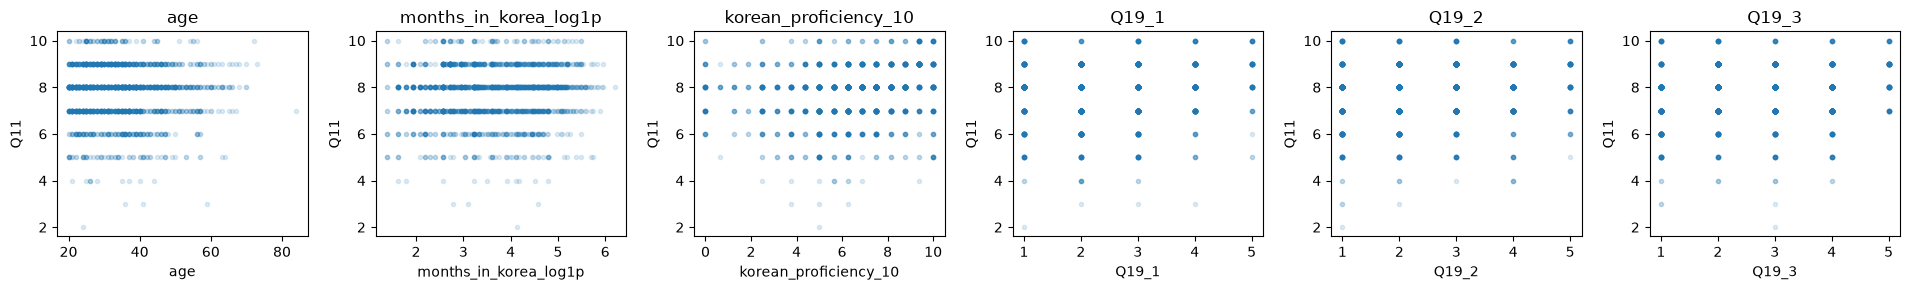

In [17]:
plot_cols=[v for v in NUMERIC+ORDINAL if train_df[v].nunique(dropna=True)>1][:6]
if plot_cols:
    fig,axes=plt.subplots(1,len(plot_cols),figsize=(max(6,len(plot_cols)*3.2),3))
    axes=np.atleast_1d(axes)
    for ax,column in zip(axes,plot_cols):
        ax.scatter(train_df[column],train_df['Q11'],alpha=0.14,s=9)
        ax.set(xlabel=column,ylabel='Q11',title=column)
    plt.tight_layout()
    plt.show()

## 6. Shared model baselines and fixed hyperparameters

Every role compares the same models with the same settings. No hyperparameter tuning in this stage. Training-only 5-fold CV chooses one winning model separately for regression and classification.

In [18]:
reg_cv = cv_compare(train_df, NOMINAL, ORDINAL, NUMERIC, task='regression')
clf_cv = cv_compare(train_df, NOMINAL, ORDINAL, NUMERIC, task='classification')
display(reg_cv)
display(clf_cv)

c:\Users\laura\OneDrive\Laura\Uni\3년\2학기\Machine Learning\Final Project\seoul_foreigners_ml_project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\laura\OneDrive\Laura\Uni\3년\2학기\Machine Learning\Final Project\seoul_foreigners_ml_project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\laura\OneDrive\Laura\Uni\3년\2학기\Machine Learning\Final Project\seoul_foreigners_ml_project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), e

,model,task,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std,cv_r2_mean,cv_r2_std
0,SVR_RBF,regression,1.001905,0.039516,0.737477,0.036109,0.210206,0.032934
1,RandomForest,regression,1.004486,0.030908,0.742574,0.033949,0.206023,0.022277
2,LinearRegression,regression,1.050867,0.042379,0.792739,0.037603,0.131065,0.039041
3,DummyMean,regression,1.128106,0.034015,0.865443,0.028179,-0.001053,0.000659


,model,task,cv_f1_mean,cv_f1_std,cv_f1_macro_mean,cv_f1_macro_std,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,cv_accuracy_mean,cv_accuracy_std,cv_roc_auc_mean,cv_roc_auc_std
0,RandomForest,classification,0.808152,0.011137,0.623081,0.020630,0.621518,0.017199,0.7140,0.016016,0.721877,0.033583
1,SVC_RBF,classification,0.801313,0.011209,0.614200,0.019926,0.613619,0.016988,0.7050,0.015890,0.712037,0.038800
2,LogisticRegression,classification,0.791025,0.004355,0.604596,0.007456,0.604420,0.006447,0.6925,0.006124,0.684246,0.025623
3,DummyMostFrequent,classification,0.791541,0.000000,0.395770,0.000000,0.500000,0.000000,0.6550,0.000000,0.500000,0.000000


## 7. Select winning models from cross-validation

Regression uses lowest CV RMSE; classification uses highest CV macro-F1. The test set does not affect model selection.

In [19]:
reg_winner = reg_cv.loc[0,'model']
clf_winner = clf_cv.loc[0,'model']
print('Selected regression model:',reg_winner)
print('Selected classifier:',clf_winner)

Selected regression model: SVR_RBF
Selected classifier: RandomForest


## 8. Evaluate the selected winners on the fixed test set

The test set is accessed for final reporting only; do not retune models based on these numbers.

In [20]:
reg_model, reg_metrics, _ = evaluate_winner(train_df,test_df,NOMINAL,ORDINAL,NUMERIC,'regression',reg_winner)
clf_model, clf_metrics, cm = evaluate_winner(train_df,test_df,NOMINAL,ORDINAL,NUMERIC,'classification',clf_winner)
display(reg_metrics)
display(clf_metrics)
display(cm)

,model,task,mae,rmse,r2
0,SVR_RBF,regression,0.70553,0.994057,0.237812


,model,task,accuracy,precision,recall,f1,f1_macro,balanced_accuracy,roc_auc
0,RandomForest,classification,0.736,0.733333,0.939024,0.823529,0.64986,0.643931,0.746685


,pred_0,pred_1
actual_0,60,112
actual_1,20,308


## 9. Model interpretation: permutation importance

Permutation importance reports how much each input contributes to the chosen model’s predictive score on held-out data. It is descriptive and **must not be used to retune** the feature set against this test split. For exploratory feature selection in Notebook 05, prefer cross-validated training evidence.

In [21]:
# Use training split for feature recommendation to avoid treating test-set importances as a feature selector.
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer

def train_importance(model, scoring):
    item=permutation_importance(model,train_df[FEATURES],train_df['Q11' if scoring=='neg_root_mean_squared_error' else 'high_satisfaction'],
                                scoring=scoring,n_repeats=5,random_state=RANDOM_STATE,n_jobs=1)
    return pd.DataFrame({'feature':FEATURES,'importance_mean':item.importances_mean,'importance_std':item.importances_std}).sort_values('importance_mean',ascending=False)

reg_importance=train_importance(reg_model,'neg_root_mean_squared_error')
clf_importance=train_importance(clf_model,'f1')
display(reg_importance.head(12))
display(clf_importance.head(12))

,feature,importance_mean,importance_std
13,korean_proficiency_10,0.085681,0.003801
9,Q20_3,0.083423,0.004873
0,SQ1,0.063281,0.004748
1,SQ2,0.060986,0.003676
8,Q20_2,0.059781,0.007048
12,months_in_korea_log1p,0.058525,0.004110
10,Q20_4,0.053035,0.003791
4,Q19_2,0.048308,0.003231
6,Q19_4,0.044913,0.003394
7,Q20_1,0.044006,0.001269


,feature,importance_mean,importance_std
13,korean_proficiency_10,0.021868,0.000848
1,SQ2,0.018863,0.003302
8,Q20_2,0.016748,0.003089
11,age,0.014291,0.001093
0,SQ1,0.012194,0.001077
9,Q20_3,0.010183,0.001296
12,months_in_korea_log1p,0.009916,0.001028
7,Q20_1,0.008312,0.001398
10,Q20_4,0.007161,0.000617
5,Q19_3,0.005704,0.001816


## 10. Export comparable results

Generated CSV results go into ignored `results/`; human-written interpretation goes into tracked `findings/`. Do not export participant-level predictions to GitHub.

In [22]:
prefix='02_language'
reg_cv.to_csv(RESULTS_DIR/f'{prefix}_regression_cv.csv',index=False)
clf_cv.to_csv(RESULTS_DIR/f'{prefix}_classification_cv.csv',index=False)
reg_metrics.to_csv(RESULTS_DIR/f'{prefix}_regression_test.csv',index=False)
clf_metrics.to_csv(RESULTS_DIR/f'{prefix}_classification_test.csv',index=False)
cm.to_csv(RESULTS_DIR/f'{prefix}_confusion_matrix.csv')
feature_table.to_csv(RESULTS_DIR/f'{prefix}_feature_audit.csv',index=False)
association_table.to_csv(RESULTS_DIR/f'{prefix}_exploratory_associations.csv',index=False)
reg_importance.to_csv(RESULTS_DIR/f'{prefix}_regression_importance.csv',index=False)
clf_importance.to_csv(RESULTS_DIR/f'{prefix}_classification_importance.csv',index=False)
print('Saved role outputs to',RESULTS_DIR)

Saved role outputs to C:\Users\laura\OneDrive\Laura\Uni\3년\2학기\Machine Learning\Final Project\seoul_foreigners_ml_project\results


## 11. Conclusions and handoff to Notebook 05

Write a separate file `findings/02_language_integration.md` using the included findings template. Explicitly document:

1. Research question and codebook-verified variable meanings.
2. Missingness and why any question is conditional.
3. Evidence from training-only EDA.
4. Cross-validation comparison and selection rationale.
5. Final regression and classification test results, including classification imbalance.
6. Interpretation of the most useful predictors, limitations, and possible social implications.
7. At most **3–5 recommended features** for Notebook 05 with rationale grounded in training CV, not test-driven selection.

**Do not claim causation from this observational dataset.**